# Attempt 1: CNN + LSTM
## Performance: Poor 55%

In [1]:
!pip install essentia

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 56.4 MB/s eta 0:00:00


In [2]:
from google.colab import drive
import zipfile
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from essentia.standard import MonoLoader
from tqdm import tqdm
import librosa
import matplotlib.pyplot as plt
import librosa.display
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models

if os.path.exists("/content/drive/MyDrive"):
    print("Drive is already mounted.")
else:
    from google.colab import drive
    drive.mount('/content/drive')

Drive is already mounted.


In [3]:
zip_path = "/content/drive/MyDrive/szakdolgozat/MASTmelody_dataset.zip"
folder_path = "/content/drive/MyDrive/szakdolgozat/MASTmelody_dataset"
extract_path = "/content/drive/MyDrive/szakdolgozat/MASTmelody_dataset"

In [4]:
csv_path = "/content/drive/MyDrive/szakdolgozat/MASTmelody_dataset/annotations/annotations.csv"
annotations = pd.read_csv(csv_path)
annotations.head()

,index,file,1Asli,5Ozan,2Asli,3Cihan,4Cihan,fullAgree,fullAgree_score,majority_score
0,0,52_mel2_per176160.wav,3.0,2.0,4.0,2.0,2.0,False,NaN,2.0
1,1,69_mel1_per1755742.wav,2.0,3.0,2.0,3.0,2.0,False,NaN,2.0
2,2,53_mel1_ref256758.wav,4.0,4.0,NaN,4.0,4.0,True,4.0,4.0
3,3,55_mel1_ref376559.wav,4.0,4.0,4.0,4.0,4.0,True,4.0,4.0
4,4,56_mel1_ref193895.wav,4.0,4.0,4.0,4.0,4.0,True,4.0,4.0


In [5]:
# ref -> reference (Piano)
# per -> performance
# Select singing only
singing_annotations = annotations[annotations["file"].str.contains("per")]
singing_annotations.head()

,index,file,1Asli,5Ozan,2Asli,3Cihan,4Cihan,fullAgree,fullAgree_score,majority_score
0,0,52_mel2_per176160.wav,3.0,2.0,4.0,2.0,2.0,False,NaN,2.0
1,1,69_mel1_per1755742.wav,2.0,3.0,2.0,3.0,2.0,False,NaN,2.0
13,13,59_mel1_per120160.wav,2.0,1.0,1.0,2.0,1.0,False,NaN,1.0
14,14,510_mel1_per174995.wav,1.0,1.0,1.0,2.0,NaN,False,NaN,1.0
19,19,53_mel2_per116558.wav,4.0,4.0,3.0,4.0,4.0,False,NaN,4.0


In [6]:
ratings_cols = ['1Asli', '5Ozan', '2Asli', '3Cihan', '4Cihan']
singing_annotations['AvgScore'] = singing_annotations[ratings_cols].mean(axis=1)
singing_annotations.head()

/tmp/ipython-input-3254644883.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  singing_annotations['AvgScore'] = singing_annotations[ratings_cols].mean(axis=1)


,index,file,1Asli,5Ozan,2Asli,3Cihan,4Cihan,fullAgree,fullAgree_score,majority_score,AvgScore
0,0,52_mel2_per176160.wav,3.0,2.0,4.0,2.0,2.0,False,NaN,2.0,2.60
1,1,69_mel1_per1755742.wav,2.0,3.0,2.0,3.0,2.0,False,NaN,2.0,2.40
13,13,59_mel1_per120160.wav,2.0,1.0,1.0,2.0,1.0,False,NaN,1.0,1.40
14,14,510_mel1_per174995.wav,1.0,1.0,1.0,2.0,NaN,False,NaN,1.0,1.25
19,19,53_mel2_per116558.wav,4.0,4.0,3.0,4.0,4.0,False,NaN,4.0,3.80


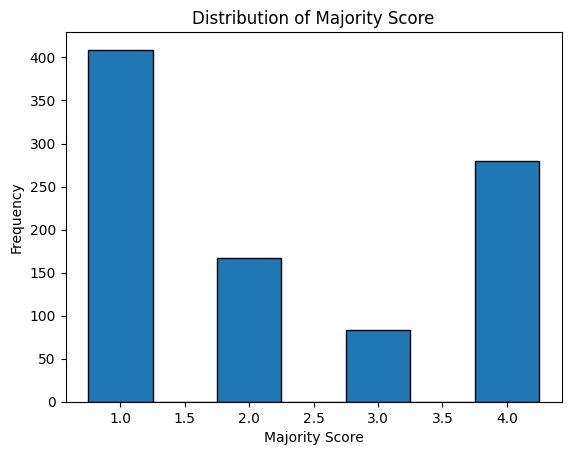

In [7]:
bin_width = 0.5

bins = np.arange(singing_annotations['majority_score'].min() - bin_width/2,
                 singing_annotations['majority_score'].max() + bin_width,
                 bin_width)

plt.hist(singing_annotations['majority_score'], bins=bins, edgecolor='black')
plt.xlabel('Majority Score')
plt.ylabel('Frequency')
plt.title('Distribution of Majority Score')
plt.show()

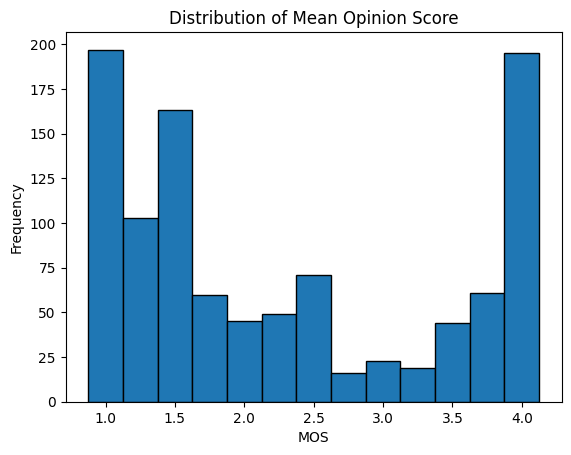

In [8]:
bin_width = 0.25

bins = np.arange(singing_annotations['AvgScore'].min() - bin_width/2,
                 singing_annotations['AvgScore'].max() + bin_width,
                 bin_width)

plt.hist(singing_annotations['AvgScore'], bins=bins, edgecolor='black')
plt.xlabel('MOS')
plt.ylabel('Frequency')
plt.title('Distribution of Mean Opinion Score')
plt.show()

In [9]:
print(singing_annotations['majority_score'].value_counts())

percentages = singing_annotations["majority_score"].value_counts(normalize=True) * 100
print(percentages)

majority_score
1.0    409
4.0    280
2.0    167
3.0     83
Name: count, dtype: int64
majority_score
1.0    43.556976
4.0    29.818956
2.0    17.784878
3.0     8.839191
Name: proportion, dtype: float64


In [10]:
missing_values = singing_annotations.isnull().sum()
print(missing_values)

# Missing values - No Noise Ceiling Analysis

index                0
file                 0
1Asli                5
5Ozan                5
2Asli               31
3Cihan               5
4Cihan              14
fullAgree            0
fullAgree_score    647
majority_score     107
AvgScore             0
dtype: int64


In [11]:
# Fill missing values with AvgScore rounded down
singing_annotations['majority_score'].fillna(singing_annotations['AvgScore'].apply(lambda x: int(x)), inplace=True)
missing_values = singing_annotations.isnull().sum()
print(missing_values)

index                0
file                 0
1Asli                5
5Ozan                5
2Asli               31
3Cihan               5
4Cihan              14
fullAgree            0
fullAgree_score    647
majority_score       0
AvgScore             0
dtype: int64


/tmp/ipython-input-4202196255.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  singing_annotations['majority_score'].fillna(singing_annotations['AvgScore'].apply(lambda x: int(x)), inplace=True)
/tmp/ipython-input-4202196255.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  singing_annotations['majority_score'].fillna(singing_annotations[

In [12]:
# fix file format
singing_annotations['file'] = singing_annotations['file'].str.replace('.wav', '.m4a')
singing_annotations.head()

/tmp/ipython-input-3605882080.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  singing_annotations['file'] = singing_annotations['file'].str.replace('.wav', '.m4a')


,index,file,1Asli,5Ozan,2Asli,3Cihan,4Cihan,fullAgree,fullAgree_score,majority_score,AvgScore
0,0,52_mel2_per176160.m4a,3.0,2.0,4.0,2.0,2.0,False,NaN,2.0,2.60
1,1,69_mel1_per1755742.m4a,2.0,3.0,2.0,3.0,2.0,False,NaN,2.0,2.40
13,13,59_mel1_per120160.m4a,2.0,1.0,1.0,2.0,1.0,False,NaN,1.0,1.40
14,14,510_mel1_per174995.m4a,1.0,1.0,1.0,2.0,NaN,False,NaN,1.0,1.25
19,19,53_mel2_per116558.m4a,4.0,4.0,3.0,4.0,4.0,False,NaN,4.0,3.80


In [13]:
# Load data with MonoLoader
audio_dir = "/content/drive/MyDrive/szakdolgozat/MASTmelody_dataset/audioFiles/MAST_melody_audio/MAST_melody_audio"

audio_data = {}
for fname in tqdm(singing_annotations['file'], desc="Loading audio files"):
    path = os.path.join(audio_dir, fname)
    if os.path.exists(path):
        audio_sig = MonoLoader(filename=path, sampleRate=8000)()
        audio_data[fname] = audio_sig
    else:
        print(f"File not found: {fname}")

Loading audio files: 100%|██████████| 1046/1046 [06:34<00:00,  2.65it/s]


In [14]:
mel_spectrograms = {}

for fname, audio_sig in tqdm(audio_data.items(), desc="Computing Mel spectrograms"):

    # Mel spectrogram
    S = librosa.feature.melspectrogram(
        y=audio_sig,
        sr=8000, # 8 khz
        n_fft=512,
        hop_length=256,
        n_mels=80 # number of Mel bands
    )

    # decibel scale
    S_db = librosa.power_to_db(S, ref=np.max)

    mel_spectrograms[fname] = S_db

Computing Mel spectrograms: 100%|██████████| 1041/1041 [00:17<00:00, 60.24it/s] 


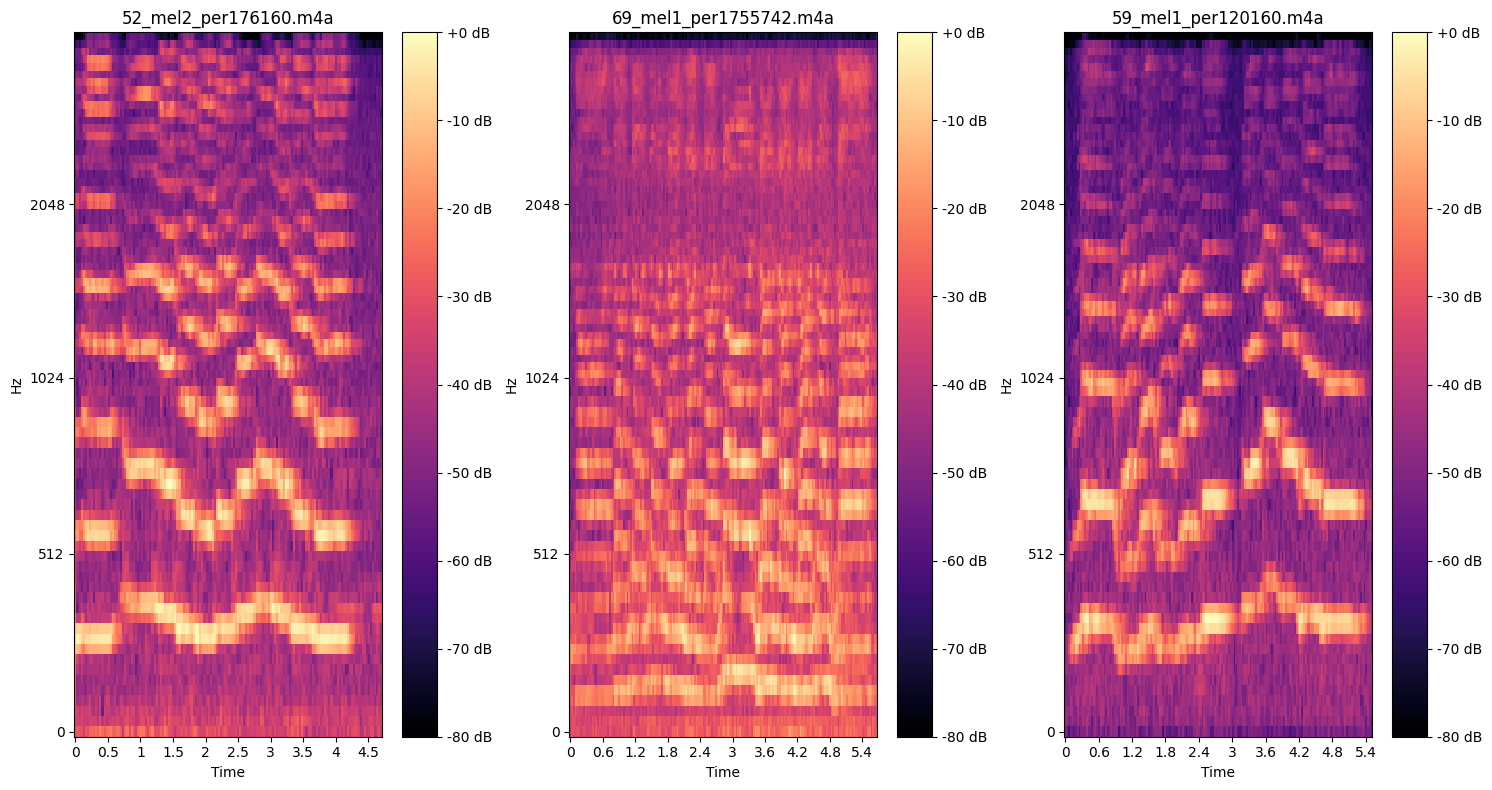

In [15]:
first_three = list(mel_spectrograms.items())[:3]

plt.figure(figsize=(15, 8))

for i, (fname, S_db) in enumerate(first_three, 1):
    plt.subplot(1, 3, i)

    # Handle if has channel dimension
    if S_db.ndim == 3:
        S_db = S_db.squeeze()

    librosa.display.specshow(
        S_db,
        sr=8000,
        hop_length=256,
        x_axis='time',
        y_axis='mel',
        cmap='magma'
    )

    plt.colorbar(format='%+2.0f dB')
    plt.title(fname)
    plt.tight_layout()

plt.show()

In [16]:
mel_df = pd.DataFrame(list(mel_spectrograms.items()), columns=['file', 'mel_spectrogram'])
mel_df.head()

,file,mel_spectrogram
0,52_mel2_per176160.m4a,"[[-31.085495, -27.755959, -30.325068, -30.0914..."
1,69_mel1_per1755742.m4a,"[[-40.597874, -29.889484, -30.222689, -31.4344..."
2,59_mel1_per120160.m4a,"[[-51.81818, -52.431126, -63.044186, -52.24917..."
3,510_mel1_per174995.m4a,"[[-46.06003, -46.535484, -48.713844, -45.139, ..."
4,53_mel2_per116558.m4a,"[[-40.929817, -43.430748, -43.296013, -42.7447..."


In [17]:
merged_df = pd.merge(singing_annotations, mel_df, on='file')
merged_df = merged_df[['file', 'majority_score', 'mel_spectrogram']]
merged_df.head()

,file,majority_score,mel_spectrogram
0,52_mel2_per176160.m4a,2.0,"[[-31.085495, -27.755959, -30.325068, -30.0914..."
1,69_mel1_per1755742.m4a,2.0,"[[-40.597874, -29.889484, -30.222689, -31.4344..."
2,59_mel1_per120160.m4a,1.0,"[[-51.81818, -52.431126, -63.044186, -52.24917..."
3,510_mel1_per174995.m4a,1.0,"[[-46.06003, -46.535484, -48.713844, -45.139, ..."
4,53_mel2_per116558.m4a,4.0,"[[-40.929817, -43.430748, -43.296013, -42.7447..."


In [18]:
missing_values = merged_df.isnull().sum()
print(missing_values)

file               0
majority_score     0
mel_spectrogram    0
dtype: int64


In [19]:
merged_df.shape

(1046, 3)

In [20]:
# Bucketing to balance data
# Poor: 1.0
# Mediocre: 2.0 or 3.0
# Good: 4.0
# Won't be fine-grained sadly

merged_df['majority_score'] = merged_df['majority_score'].apply(lambda x: 0 if x == 1.0 else (1 if x in [2.0, 3.0] else 2))
merged_df.head()

,file,majority_score,mel_spectrogram
0,52_mel2_per176160.m4a,1,"[[-31.085495, -27.755959, -30.325068, -30.0914..."
1,69_mel1_per1755742.m4a,1,"[[-40.597874, -29.889484, -30.222689, -31.4344..."
2,59_mel1_per120160.m4a,0,"[[-51.81818, -52.431126, -63.044186, -52.24917..."
3,510_mel1_per174995.m4a,0,"[[-46.06003, -46.535484, -48.713844, -45.139, ..."
4,53_mel2_per116558.m4a,2,"[[-40.929817, -43.430748, -43.296013, -42.7447..."


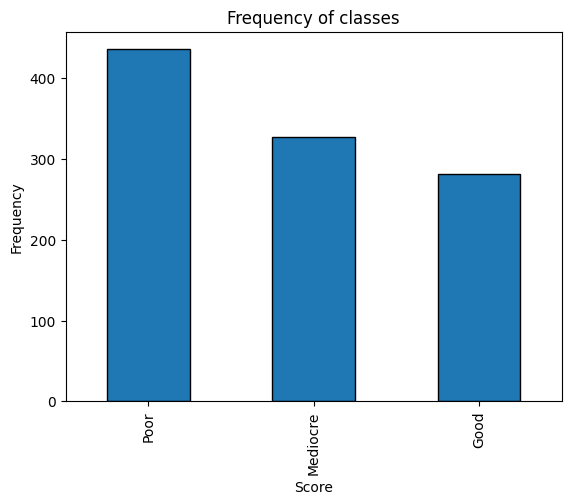

In [21]:
freq = merged_df['majority_score'].value_counts().sort_index()

freq.plot(kind='bar', edgecolor='black')
plt.xticks(ticks=[0, 1, 2], labels=['Poor', 'Mediocre', 'Good'])
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.title('Frequency of classes')
plt.show()

In [22]:
num_classes = 3
y = tf.keras.utils.to_categorical(merged_df['majority_score'], num_classes)

In [23]:
# Train and temp
train_df, temp_df = train_test_split(
    merged_df,
    test_size=0.25,
    random_state=42,
    stratify=merged_df['majority_score']
)

# Validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.4,
    random_state=42,
    stratify=temp_df['majority_score']
)

print(f"Train: {len(train_df)} ({len(train_df)/len(merged_df)*100:.1f}%)")
print(f"Val: {len(val_df)} ({len(val_df)/len(merged_df)*100:.1f}%)")
print(f"Test: {len(test_df)} ({len(test_df)/len(merged_df)*100:.1f}%)")

Train: 784 (75.0%)
Val: 157 (15.0%)
Test: 105 (10.0%)


In [24]:
def build_hybrid_model(n_mels=80, lstm_hidden=128, output_dim=3):
    # In: (n_mels, n_frames, 1) None -> Variable length
    inputs = layers.Input(shape=(n_mels, None, 1))

    # CNN: Extract features
    x = layers.Conv2D(64, (3,3), padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2,2))(x)

    x = layers.Conv2D(64, (3,3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2,2))(x)

    # Transform shape
    # (batch, n_mels', n_frames', channels) -> (batch, time, features)
    x = layers.Permute((2,1,3))(x)
    x = layers.Reshape((-1, x.shape[-2] * x.shape[-1]))(x)

    # LSTM
    x = layers.Bidirectional(layers.LSTM(lstm_hidden, return_sequences=True, dropout=0.3))(x)

    x = layers.GlobalAveragePooling1D()(x)

    # Out
    outputs = layers.Dense(output_dim, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model

model = build_hybrid_model()
model.summary()

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 80, None, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 80, None, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 80, None, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 40, None, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, None, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 40, None, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, None, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, None, 20, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, None, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, None, 256)      │     1,442,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,481,667 (5.65 MB)

 Trainable params: 1,481,411 (5.65 MB)

 Non-trainable params: 256 (1.00 KB)

In [25]:
train_df, temp_df = train_test_split(merged_df,
                                     test_size=0.2,
                                     stratify=merged_df['majority_score'])

val_df, test_df = train_test_split(temp_df,
                                   test_size=0.5,
                                   stratify=temp_df['majority_score'])

In [26]:
num_classes = 3

X_train = train_df['mel_spectrogram'].tolist()
y_train = tf.keras.utils.to_categorical(train_df['majority_score'], num_classes)

X_val = val_df['mel_spectrogram'].tolist()
y_val = tf.keras.utils.to_categorical(val_df['majority_score'], num_classes)

X_test = test_df['mel_spectrogram'].tolist()
y_test = tf.keras.utils.to_categorical(test_df['majority_score'], num_classes)

In [27]:
num_classes = 3

def preprocess(x, y):
    # Channel dimension (n_mels, time) -> (n_mels, time, 1)
    x = tf.expand_dims(x, -1)
    return x, y

def data_generator(X, y):
    for mel, label in zip(X, y):
        yield mel.astype(np.float32), label.astype(np.float32)



# Create datasets
train_ds = tf.data.Dataset.from_generator(
    lambda: data_generator(X_train, y_train),
    output_signature=(
        tf.TensorSpec(shape=(80, None), dtype=tf.float32),
        tf.TensorSpec(shape=(num_classes,), dtype=tf.float32)
    )
)

val_ds = tf.data.Dataset.from_generator(
    lambda: data_generator(X_val, y_val),
    output_signature=(
        tf.TensorSpec(shape=(80, None), dtype=tf.float32),
        tf.TensorSpec(shape=(num_classes,), dtype=tf.float32)
    )
)

test_ds = tf.data.Dataset.from_generator(
    lambda: data_generator(X_test, y_test),
    output_signature=(
        tf.TensorSpec(shape=(80, None), dtype=tf.float32),
        tf.TensorSpec(shape=(num_classes,), dtype=tf.float32)
    )
)

# Preproc, padding, batching
train_ds = (
    train_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .padded_batch(64, padded_shapes=([80, None, 1], [num_classes]))
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .padded_batch(64, padded_shapes=([80, None, 1], [num_classes]))
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(preprocess)
    .padded_batch(64, padded_shapes=([80, None, 1], [num_classes]))
)

In [28]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor="val_loss"),
    tf.keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5),
    tf.keras.callbacks.ModelCheckpoint("CNN_LSTM_best_model.keras", save_best_only=True)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/50
     14/Unknown 22s 780ms/step - accuracy: 0.3666 - loss: 1.2013

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


14/14 ━━━━━━━━━━━━━━━━━━━━ 23s 857ms/step - accuracy: 0.3665 - loss: 1.2007 - val_accuracy: 0.2952 - val_loss: 1.1984 - learning_rate: 0.0010
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 129ms/step - accuracy: 0.4317 - loss: 1.0610 - val_accuracy: 0.2667 - val_loss: 1.2362 - learning_rate: 0.0010
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 142ms/step - accuracy: 0.4322 - loss: 1.0560 - val_accuracy: 0.4190 - val_loss: 1.1146 - learning_rate: 0.0010
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 152ms/step - accuracy: 0.4797 - loss: 1.0174 - val_accuracy: 0.4857 - val_loss: 1.0876 - learning_rate: 0.0010
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.4480 - loss: 1.0250 - val_accuracy: 0.4952 - val_loss: 1.0510 - learning_rate: 0.0010
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.4933 - loss: 0.9881 - val_accuracy: 0.5143 - val_loss: 1.0334 - learning_rate: 0.0010
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.4992 - loss: 0.9706 - val_accura

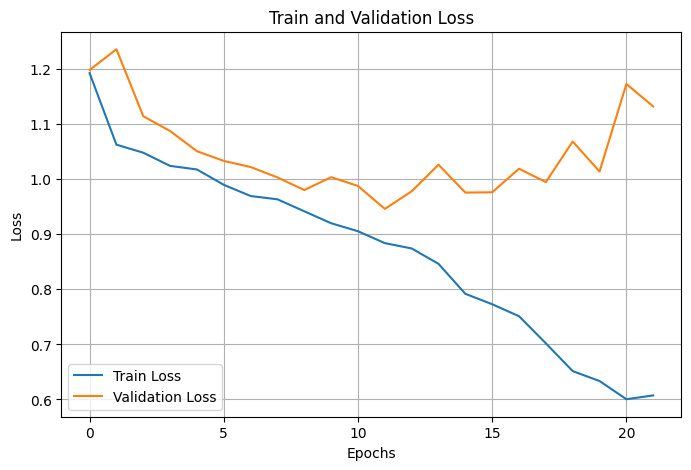

In [29]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Train and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Overfitting
# Regression instead? How to handle uneven data?

In [32]:
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.concatenate([y for x, y in test_ds], axis=0)
if len(y_true.shape) > 1 and y_true.shape[1] > 1:
    y_true = np.argmax(y_true, axis=1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [33]:
# F1 score: weighted, macro
# Confusion matrix

from sklearn.metrics import f1_score, confusion_matrix, classification_report

f1 = f1_score(y_true, y_pred, average='macro')
print("F1 Score (Macro):", f1)

f1 = f1_score(y_true, y_pred, average='weighted')
print("F1 Score (Weighted):", f1)

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

F1 Score (Macro): 0.5455940943385985
F1 Score (Weighted): 0.559538030877552
Confusion Matrix:
 [[32  2  9]
 [12  7 14]
 [ 2  4 23]]


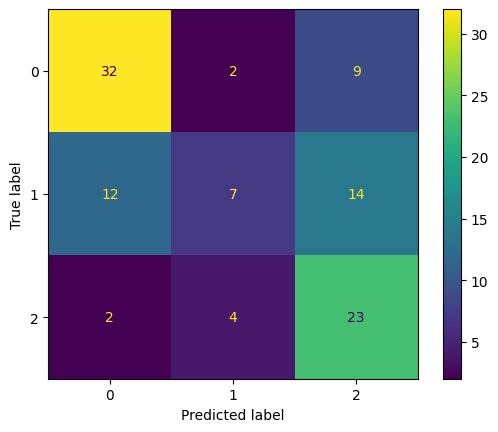

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [34]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.70      0.74      0.72        43
           1       0.54      0.21      0.30        33
           2       0.50      0.79      0.61        29

    accuracy                           0.59       105
   macro avg       0.58      0.58      0.55       105
weighted avg       0.59      0.59      0.56       105



In [36]:
model.save("/content/drive/MyDrive/models/01_CNN_LSTM_model.keras")